# Project 2 starter: quantum machine learning classification

Setup and building blocks for [Project 2](../../content/outline/projects.md). The notebook is organised around the four core elements, in the same order as the main tasks. Code you need but that isn't the point of the project (loading data, evaluating batches of circuits efficiently, counting the cost, a training loop, noisy simulation) is provided. The parts marked `TODO` are for you to write, and each has a check so you know when it works. How far you take the investigation from here is up to you. For long training runs, move your code into a script and use the HPC.

In [1]:
# ---- Settings: change these to suit your investigation ----
SETTINGS = dict(
    DATASET="mnist",       # "mnist" or "fashion"
    CLASSES=(3, 6),        # the two classes to separate
    N_TRAIN=400, N_TEST=400,
    SEED=1234,
)
DATASET, CLASSES, SEED = SETTINGS["DATASET"], SETTINGS["CLASSES"], SETTINGS["SEED"]
N_TRAIN, N_TEST = SETTINGS["N_TRAIN"], SETTINGS["N_TEST"]

In [2]:
import contextlib, io, json, time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torchvision

from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import SparsePauliOp
from qiskit_aer.primitives import EstimatorV2 as AerEstimator
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime import SamplerV2 as Sampler
from qiskit_ibm_runtime.fake_provider import FakeFez

rng = np.random.default_rng(SEED)
DATA_DIR = Path("../data") if Path("../data").exists() else Path("data")

## Loading the data

`load_pair` returns a random (but reproducible) subset of images of the two chosen classes, scaled to $[0,1]$, with labels $+1$ for the first class and $-1$ for the second.

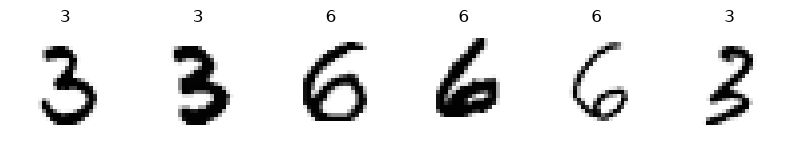

In [3]:
FASHION_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
                 "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

def load_pair(train, n):
    cls = torchvision.datasets.MNIST if DATASET == "mnist" else torchvision.datasets.FashionMNIST
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):   # hide download progress
        ds = cls(DATA_DIR, train=train, download=True)
    x, y = ds.data.numpy() / 255.0, ds.targets.numpy()
    keep = np.isin(y, CLASSES)
    x, y = x[keep], y[keep]
    idx = rng.choice(len(x), n, replace=False)
    return x[idx], np.where(y[idx] == CLASSES[0], 1.0, -1.0)

x_train, Y_train = load_pair(train=True, n=N_TRAIN)
x_test, Y_test = load_pair(train=False, n=N_TEST)

def class_name(label):
    c = CLASSES[0] if label > 0 else CLASSES[1]
    return FASHION_NAMES[c] if DATASET == "fashion" else str(c)

fig, axes = plt.subplots(1, 6, figsize=(10, 2))
for ax, img, lab in zip(axes, x_train, Y_train):
    ax.imshow(img, cmap="Greys"); ax.set_title(class_name(lab)); ax.axis("off")
plt.show()

## 1. Circuit design

A QNN here is any circuit with **data parameters** `x` and **weight parameters** `w`, whose output is $f=\langle Z_0\rangle$. The `QNN` class evaluates $f$ for whole batches of images and weights in one Aer call, and counts the number of circuit evaluations (the **cost**).

`angle_encoding_qnn` is the baseline from Lecture 6: the central row of a $9\times 9$ image, angle encoding, and layers of rotations and CNOTs into qubit 0. Your other encodings and circuits should return a `QNN` too.

In [4]:
class QNN:
    def __init__(self, circuit, x_params, w_params, shots=None):
        self.qc, self.x, self.w = circuit, list(x_params), list(w_params)
        self.obs = SparsePauliOp("I" * (circuit.num_qubits - 1) + "Z")
        precision = 0.0 if shots is None else 1 / np.sqrt(shots)     # shots=None: exact expectation values
        self.estimator = AerEstimator(options={"default_precision": precision})
        self.n_evaluations = 0

    def predict(self, X, W):
        # <Z0> for images X (..., n_x) and weights W (..., n_w) with matching leading shapes.
        W = np.broadcast_to(W, X.shape[:-1] + (len(self.w),))
        evs = self.estimator.run([(self.qc, self.obs, {tuple(self.x): X, tuple(self.w): W})]).result()[0].data.evs
        self.n_evaluations += int(np.prod(evs.shape))
        return evs


def shrink(x, size):
    t = torch.tensor(x, dtype=torch.float32)[:, None]
    return torch.nn.functional.interpolate(t, size=(size, size), mode="area")[:, 0].numpy()

def central_row(x, size=9):
    return shrink(x, size)[:, size // 2, :]

def angle_encoding_qnn(n_qubits, n_layers, shots=None):
    x = ParameterVector("x", n_qubits)
    w = ParameterVector("w", n_layers * (2 * (n_qubits - 1) + 1) * 3)
    qc = QuantumCircuit(n_qubits)
    for i in range(n_qubits):
        qc.ry(np.pi * x[i], i)
    k = 0
    def rotation(q):
        nonlocal k
        qc.rz(w[k], q); qc.ry(w[k + 1], q); qc.rz(w[k + 2], q); k += 3
    for _ in range(n_layers):
        for i in range(1, n_qubits):
            rotation(0); rotation(i); qc.cx(i, 0)
        rotation(0)
    return QNN(qc, x, w, shots)

X_train, X_test = central_row(x_train), central_row(x_test)
qnn = angle_encoding_qnn(n_qubits=9, n_layers=1)
W0 = 0.01 * rng.uniform(size=len(qnn.w))
print(f"{len(qnn.w)} weights; data shape {X_train.shape}")

51 weights; data shape (400, 9)


## 2. Measurement and uncertainty

`QNN(..., shots=N)` adds the statistical noise of $N$ shots to every expectation value. `evaluate` returns the accuracy with its binomial standard error $\sqrt{a(1-a)/N_\text{test}}$, and the hinge loss.

In [5]:
def hinge_loss(f, Y):
    return np.mean(np.maximum(0, 1 - Y * f), axis=-1)

def evaluate(qnn, X, Y, W):
    f = qnn.predict(X, W)
    acc = np.mean(np.sign(f) == Y)
    return {"accuracy": acc, "accuracy_err": np.sqrt(acc * (1 - acc) / len(Y)), "loss": hinge_loss(f, Y)}

print("untrained:", {k: round(float(v), 3) for k, v in evaluate(qnn, X_test, Y_test, W0).items()})

untrained: {'accuracy': 0.492, 'accuracy_err': 0.025, 'loss': 1.004}


## 3. Optimisation and gradients

### Gradient methods (to implement)

Implement the three gradient methods from [Lecture 5](../../content/lectures/lecture5.md). Each takes a function `f` and parameters `theta` (shape `(P,)`), and returns an estimate of $\nabla f$. `f` accepts a whole **batch** of parameter sets, with shape `(N, P)`, and returns `N` values. Evaluate everything you need in a single call to `f`, which is much faster.

`check_gradient` compares your implementation with a high-accuracy reference using exact (noiseless) values, and prints the relative error. Finite difference (with a small step) and parameter shift should agree to many digits. SPSA is random, so its check averages many estimates. The error of the average only falls as $1/\sqrt{n}$, so a relative error of order $10^{-1}$ to $10^{-2}$ is expected.

Here `f` is the hinge loss on a batch of images, as a function of the weights: `batch_loss(qnn, X, Y)` returns such a function. Finite differences and SPSA can be applied to the loss directly. The parameter-shift rule cannot. Why not? Instead, write `parameter_shift_loss_gradient`: apply the parameter shift to $f=\langle Z_0\rangle$ for each image, then use the chain rule. You can still use the general `parameter_shift_gradient` for this.

In [6]:
def finite_difference_gradient(f, theta, c=0.1):
    """Central finite-difference estimate of the gradient of f at theta."""
    raise NotImplementedError("TODO")

def spsa_gradient(f, theta, c=0.1, rng=rng):
    """SPSA estimate of the gradient of f at theta, using only two evaluations of f."""
    raise NotImplementedError("TODO")

def parameter_shift_gradient(f, theta):
    """Parameter-shift gradient of f at theta. Exact when f is an expectation value of a circuit
    whose parameters each appear once, in a Pauli rotation gate."""
    raise NotImplementedError("TODO")


def check_gradient(gradient_fn, f_exact, theta, n_average=1, **kwargs):
    """Compare gradient_fn(f_exact, theta) (averaged over n_average estimates) with a reference."""
    try:
        g = np.mean([gradient_fn(f_exact, theta, **kwargs) for _ in range(n_average)], axis=0)
    except NotImplementedError:
        print(f"{gradient_fn.__name__}: not implemented yet")
        return
    eps, P = 1e-5, len(theta)
    vals = f_exact(theta + np.vstack([eps * np.eye(P), -eps * np.eye(P)]))
    reference = (vals[:P] - vals[P:]) / (2 * eps)
    rel = np.max(np.abs(g - reference)) / np.max(np.abs(reference))
    print(f"{gradient_fn.__name__}: relative error = {rel:.1e}" + (f" (average of {n_average})" if n_average > 1 else ""))


def batch_loss(qnn, X, Y):
    """Return the function W_sets (N, P) -> hinge loss on the batch (X, Y) for each set of weights."""
    def f(W_sets):
        W_sets = np.atleast_2d(W_sets)
        F = qnn.predict(np.broadcast_to(X, (len(W_sets),) + X.shape), W_sets[:, None, :])   # (N, batch)
        return hinge_loss(F, Y)
    return f

def parameter_shift_loss_gradient(qnn, X, Y, W):
    """Gradient of the hinge loss on the batch (X, Y) at W, from parameter-shift gradients of <Z0>."""
    raise NotImplementedError("TODO")

In [7]:
X_check, Y_check = X_train[:20], Y_train[:20]
W_check = rng.uniform(0, 2 * np.pi, len(qnn.w))
f_exact = batch_loss(qnn, X_check, Y_check)          # qnn has shots=None: exact

check_gradient(finite_difference_gradient, f_exact, W_check, c=1e-4)
check_gradient(spsa_gradient, f_exact, W_check, n_average=2000, c=1e-4)
def parameter_shift_loss(f, W):                       # adapts your function to check_gradient's interface
    return parameter_shift_loss_gradient(qnn, X_check, Y_check, W)

check_gradient(parameter_shift_loss, f_exact, W_check)

finite_difference_gradient: not implemented yet
spsa_gradient: not implemented yet
parameter_shift_loss: not implemented yet


### Training

`train` trains a QNN with mini-batches and the Adam optimiser, using any gradient function `gradient_fn(qnn, X, Y, W)`. It records the loss, the training and test accuracy, and the cost. For example:

```python
spsa = lambda qnn, X, Y, W: spsa_gradient(batch_loss(qnn, X, Y), W, c=0.1)
W, history = train(qnn, spsa, epochs=10)
W, history = train(qnn, parameter_shift_loss_gradient, epochs=10)
```

In [8]:
def train(qnn, gradient_fn, epochs=8, batch_size=40, lr=0.1, W0=None, seed=SEED, verbose=True):
    r = np.random.default_rng(seed)
    W = 0.01 * r.uniform(size=len(qnn.w)) if W0 is None else np.array(W0, dtype=float)
    m, v, t = np.zeros_like(W), np.zeros_like(W), 0                     # Adam state
    cost0 = qnn.n_evaluations
    history = {k: [] for k in ["loss", "train_acc", "test_acc", "test_acc_err", "cost"]}
    for epoch in range(epochs):
        for idx in np.array_split(r.permutation(len(X_train)), len(X_train) // batch_size):
            g = gradient_fn(qnn, X_train[idx], Y_train[idx], W)
            t += 1
            m = 0.9 * m + 0.1 * g
            v = 0.999 * v + 0.001 * g**2
            W = W - lr * (m / (1 - 0.9**t)) / (np.sqrt(v / (1 - 0.999**t)) + 1e-8)
        n_before = qnn.n_evaluations                                     # don't count monitoring as cost
        tr, te = evaluate(qnn, X_train, Y_train, W), evaluate(qnn, X_test, Y_test, W)
        qnn.n_evaluations = n_before
        for k, val in [("loss", tr["loss"]), ("train_acc", tr["accuracy"]), ("test_acc", te["accuracy"]),
                       ("test_acc_err", te["accuracy_err"]), ("cost", qnn.n_evaluations - cost0)]:
            history[k].append(val)
        if verbose:
            print(f"epoch {epoch + 1}: loss {tr['loss']:.3f}  train acc {tr['accuracy']:.3f}  "
                  f"test acc {te['accuracy']:.3f} ± {te['accuracy_err']:.3f}  cost {qnn.n_evaluations - cost0}")
    return W, {k: np.array(val) for k, val in history.items()}

## 4. Noise

`noisy_predict` evaluates a trained QNN on a (fake) backend with realistic noise. It transpiles the circuit for the device, measures qubit 0, and estimates $\langle Z_0\rangle = p(0)-p(1)$ for each image. It is much slower than `QNN.predict`, so use it on a test set of modest size. To run on real hardware (bonus), pass a real backend.

In [9]:
def noisy_predict(qnn, X, W, backend, shots=1000, seed=SEED):
    qc = qnn.qc.copy()
    qc.add_register(__import__("qiskit").ClassicalRegister(1, "meas"))
    qc.measure(0, 0)
    tqc = generate_preset_pass_manager(backend=backend, optimization_level=3, seed_transpiler=seed).run(qc)
    order = list(tqc.parameters)                                  # parameter order of the transpiled circuit
    values = {p: X[:, i] for i, p in enumerate(qnn.x)} | {p: np.full(len(X), W[i]) for i, p in enumerate(qnn.w)}
    sampler = Sampler(mode=backend)
    if backend.name.startswith("fake"):
        sampler.options.simulator.seed_simulator = seed
    res = sampler.run([(tqc, np.column_stack([values[p] for p in order]))], shots=shots).result()[0]
    counts = [res.data.meas.get_counts(loc=i) for i in range(len(X))]
    return np.array([(c.get("0", 0) - c.get("1", 0)) / shots for c in counts])

f_ideal = qnn.predict(X_test[:20], W0)
f_noisy = noisy_predict(qnn, X_test[:20], W0, FakeFez())
print("noiseless:", f_ideal[:5].round(3))
print("noisy    :", f_noisy[:5].round(3))

noiseless: [ 0.155 -0.     0.16  -0.006  0.003]
noisy    : [0.176 0.03  0.164 0.008 0.05 ]


## Saving results

Save results as you go, so you never have to re-run long calculations just to change a plot.

In [10]:
def save_results(name, **arrays):
    """Save numpy arrays to results/<name>.npz, with the group settings in results/<name>.json."""
    out = Path("results"); out.mkdir(exist_ok=True)
    np.savez(out / f"{name}.npz", **arrays)
    (out / f"{name}.json").write_text(json.dumps({**SETTINGS, "time": time.ctime()}, indent=2, default=str))